# APPM-5370 HW4

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.signal import find_peaks
from scipy.fft import rfft, irfft, next_fast_len

### 1d
Based on oct21 lecture notes & given ipynb

In [3]:
ETA, TAU_E, W_EI, W_IE = 4.0, 5.0, 10.0, 10.0
E_BAR = I_BAR = 0.1

def logit_scaled(z, eta=ETA):
    return np.log(z/(1-z))/eta

def wc_parameters(tau_I, eps):
    w_hopf = (1 + TAU_E/tau_I)/(ETA*E_BAR*(1-E_BAR))
    w_EE = (1 + eps)*w_hopf
    p_E = logit_scaled(E_BAR) - w_EE*E_BAR + W_EI*I_BAR
    p_I = logit_scaled(I_BAR) - W_IE*E_BAR
    return w_hopf, w_EE, p_E, p_I

def wc_rhs(t, y, tau_I, w_EE, p_E, p_I):
    E, I = y
    return [(-E + expit(ETA*(w_EE*E-W_EI*I+p_E)))/TAU_E,
            (-I + expit(ETA*(W_IE*E+p_I)))/tau_I]

def linear_frequency(tau_I):
    B = ETA**2*W_EI*W_IE*E_BAR*(1-E_BAR)*I_BAR*(1-I_BAR)/TAU_E
    omega2 = B/tau_I - 1/tau_I**2
    return 1000*np.sqrt(omega2)/(2*np.pi) if omega2 > 0 else np.nan

print('Check: tau_I=10, Hopf w_EE =',wc_parameters(10, 0)[0])
print('Linear frequency at tau_I=10 =', round(linear_frequency(10), 4), 'Hz')

Check: tau_I=10, Hopf w_EE = 4.166666666666666
Linear frequency at tau_I=10 = 79.45 Hz


,tau_I,epsilon,amplitude,period_ms,frequency_Hz,lag_degrees
0,10,0.005,0.0197,12.6991,78.7457,73.5486
1,10,0.010,0.0279,12.8112,78.0565,71.4039
2,10,0.020,0.0394,13.0355,76.7134,68.3591
3,10,0.050,0.0621,13.7064,72.9587,62.5042
4,10,0.100,0.0874,14.8220,67.4674,56.5413
5,10,0.200,0.1231,17.0832,58.5369,49.7324


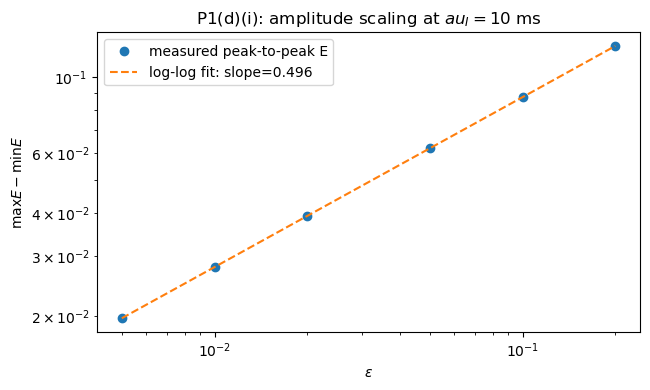

Fitted slope = 0.4964 (supercritical Hopf expects ~0.5)


In [7]:
# settled peaks and amplitude
def wc_measure(tau_I, eps, total_time=None, late_window=None):
    _, wEE, pE, pI = wc_parameters(tau_I, eps)
    if total_time is None:
        total_time = max(4000.0, 110.0 / eps) if tau_I == 10 else 5000.0
    if late_window is None:
        late_window = min(1600., total_time*0.25)
    sol = solve_ivp(wc_rhs, (0, total_time), [0.101, 0.1],
                    args=(tau_I, wEE, pE, pI), method='DOP853',
                    rtol=1e-9, atol=1e-11, dense_output=True)
    if not sol.success:
        raise RuntimeError(sol.message)
    # Dense sampling of only late-time oscillations.
    dt = min(0.04, 0.002*1000/max(linear_frequency(tau_I), 1))
    ts = np.arange(total_time-late_window, total_time, dt)
    Es, Is = sol.sol(ts)
    pkE, _ = find_peaks(Es, prominence=1e-5)
    pkI, _ = find_peaks(Is, prominence=1e-5)
    if len(pkE) < 5 or len(pkI) < 5:
        raise RuntimeError(f'Not enough settled peaks at tau_I={tau_I}, eps={eps}')
    Te = np.mean(np.diff(ts[pkE]))
    lag_times = []
    for p in pkE[1:-1]:
        q = pkI[pkI > p]
        if len(q) and 0 < (ts[q[0]]-ts[p]) < Te:
            lag_times.append(ts[q[0]]-ts[p])
    lag_degrees = 360*np.mean(lag_times)/Te
    return dict(tau_I=tau_I, epsilon=eps, amplitude=float(Es.max()-Es.min()),
                period_ms=Te, frequency_Hz=1000/Te, lag_degrees=lag_degrees,
                t=ts, E=Es, I=Is)

eps_values = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
wc_eps_runs = [wc_measure(10, eps) for eps in eps_values]
p1i = pd.DataFrame([{k:v for k,v in r.items() if k not in ('t','E','I')} for r in wc_eps_runs])
display(p1i.round(4))

slope, intercept = np.polyfit(np.log(p1i.epsilon), np.log(p1i.amplitude), 1)
fig, ax = plt.subplots(figsize=(6.6, 4))
ax.loglog(p1i.epsilon, p1i.amplitude, 'o', label='measured peak-to-peak E')
xx = np.geomspace(min(eps_values), max(eps_values), 200)
ax.loglog(xx, np.exp(intercept)*xx**slope, '--', label=f'log-log fit: slope={slope:.3f}')
ax.set(xlabel=r'$\epsilon$', ylabel=r'$\max E-\min E$',
       title='P1(d)(i): amplitude scaling at $\tau_I=10$ ms')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Fitted slope = {slope:.4f} (supercritical Hopf expects ~0.5)')

,tau_I_ms,simulated_Hz,linear_Hz,difference_Hz
0,2.0,157.0562,162.7744,-5.7181
1,3.0,133.3964,138.0974,-4.7010
2,5.0,106.3562,110.0818,-3.7257
3,7.5,88.0150,91.1254,-3.1104
4,10.0,76.7134,79.4500,-2.7366
5,15.0,63.0214,65.3031,-2.2817
6,20.0,54.7362,56.7405,-2.0043


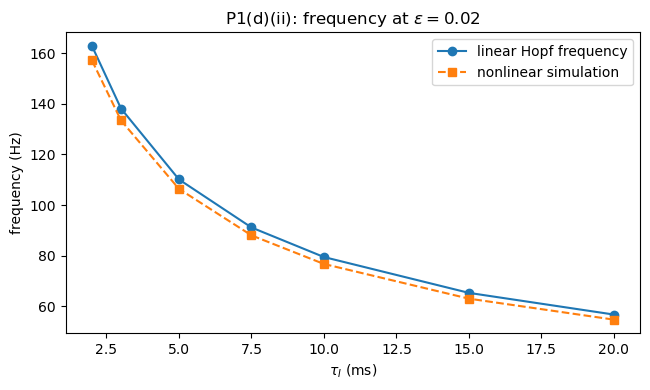

In [9]:
#freq vs inhibitory
tau_values = [2, 3, 5, 7.5, 10, 15, 20]
wc_tau_runs = [wc_measure(tau, 0.02) for tau in tau_values]
p1ii = pd.DataFrame([{'tau_I_ms': r['tau_I'],
                       'simulated_Hz': r['frequency_Hz'],
                       'linear_Hz': linear_frequency(r['tau_I'])} for r in wc_tau_runs])
p1ii['difference_Hz'] = p1ii.simulated_Hz - p1ii.linear_Hz
display(p1ii.round(4))
fig, ax = plt.subplots(figsize=(6.6, 4))
ax.plot(p1ii.tau_I_ms, p1ii.linear_Hz, 'o-', label='linear Hopf frequency')
ax.plot(p1ii.tau_I_ms, p1ii.simulated_Hz, 's--', label='nonlinear simulation')
ax.set(xlabel=r'$\tau_I$ (ms)', ylabel='frequency (Hz)',
       title='P1(d)(ii): frequency at $\epsilon=0.02$')
ax.legend(); plt.tight_layout(); plt.show()

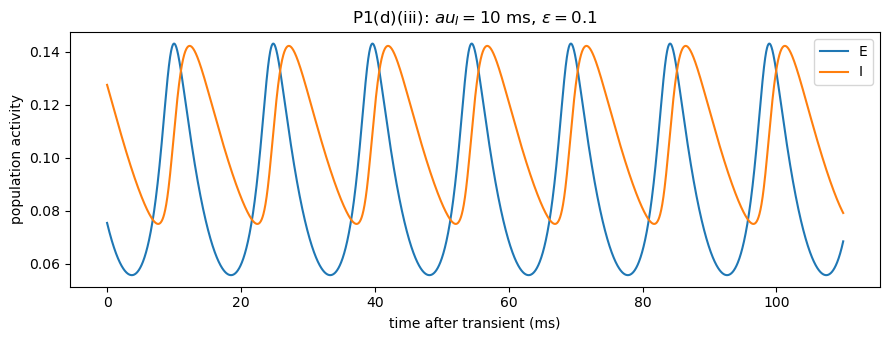

P1(d): increasing epsilon makes amplitude/period grow; lag decreases.
Near-zero amplitude with slope ~1/2 supports a supercritical Hopf.


In [11]:
#nonlinear E I time series
r = next(r for r in wc_eps_runs if np.isclose(r['epsilon'], 0.1))
mask = r['t'] > r['t'][-1]-110
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(r['t'][mask]-r['t'][mask][0], r['E'][mask], label='E')
ax.plot(r['t'][mask]-r['t'][mask][0], r['I'][mask], label='I')
ax.set(xlabel='time after transient (ms)', ylabel='population activity',
       title='P1(d)(iii): $\tau_I=10$ ms, $\epsilon=0.1$')
ax.legend(); plt.tight_layout(); plt.show()
print('P1(d): increasing epsilon makes amplitude/period grow; lag decreases.')
print('Near-zero amplitude with slope ~1/2 supports a supercritical Hopf.')

## 2d
Based on oct 23 lecture notes & given ipynb

In [12]:
W_R, BETA, G, TAU_A, ETA_R = 0.8, 1.0, 2.0, 120.0, 1000.0

def rivalry_rhs(t, y, IL, IR, w=W_R):
    uL, uR, aL, aR = y
    return [-uL + expit(ETA_R*(w*uL - BETA*uR - G*aL + IL)),
            -uR + expit(ETA_R*(w*uR - BETA*uL - G*aR + IR)),
            (-aL+uL)/TAU_A, (-aR+uR)/TAU_A]

def rivalry_run(IL, IR=1.3, w=W_R):
    tf = 30*TAU_A
    sol = solve_ivp(rivalry_rhs, (0,tf), [1,0,0,0],
                    args=(IL,IR,w), method='LSODA',
                    rtol=2e-8, atol=2e-10, max_step=0.3,
                    dense_output=True)
    if not sol.success: raise RuntimeError(sol.message)
    #uniform sampling: accurately locate the uL-uR=0 crossings.
    t = np.arange(0,tf,0.2)
    uL,uR,aL,aR = sol.sol(t)
    return t,uL,uR,aL,aR

In [14]:
#detect handovers, discard first 3
def rivalry_durations(run, discard=3):
    t, uL, uR, _, _ = run
    diff = uL-uR
    ixs = np.flatnonzero((diff[:-1]*diff[1:]) < 0)
    transitions = []
    for i in ixs:
        # Require unequivocal dominance before and after the crossing.
        left = diff[max(0,i-10):i+1]
        right = diff[i+1:min(len(diff),i+12)]
        if not (np.max(np.abs(left)) > 0.5 and np.max(np.abs(right)) > 0.5):
            continue
        tc = t[i] - diff[i]*(t[i+1]-t[i])/(diff[i+1]-diff[i])
        transitions.append(tc)
    transitions = np.array(transitions)
    if len(transitions) < discard+4:
        raise RuntimeError('Too few handovers; check dominance threshold or simulation time')
    times = np.diff(transitions)
    winner = np.array(['L' if np.interp((a+b)/2, t, diff)>0 else 'R'
                       for a,b in zip(transitions[:-1],transitions[1:])])
    times, winner = times[discard:], winner[discard:]
    return dict(TL=np.mean(times[winner=='L']), TR=np.mean(times[winner=='R']),
                all_durations=times, winners=winner, handovers=transitions)

def analytic_rivalry(IL, IR=1.3):
    BL, BR = (IL-BETA)/G, (IR-BETA)/G
    TL = float(TAU_A * np.log((1 - BL) / BR))
    TR = float(TAU_A * np.log((1 - BR) / BL))
    return BL, BR, TL, TR

run_equal = rivalry_run(1.3)
measure_equal = rivalry_durations(run_equal)
print('Analytic (TL,TR)=',analytic_rivalry(1.3)[2:])
print('Simulated (TL,TR)=',measure_equal['TL'],measure_equal['TR'])

Analytic (TL,TR)= (208.15212664657275, 208.15212664657275)
Simulated (TL,TR)= 207.49235248463688 207.49113656764817


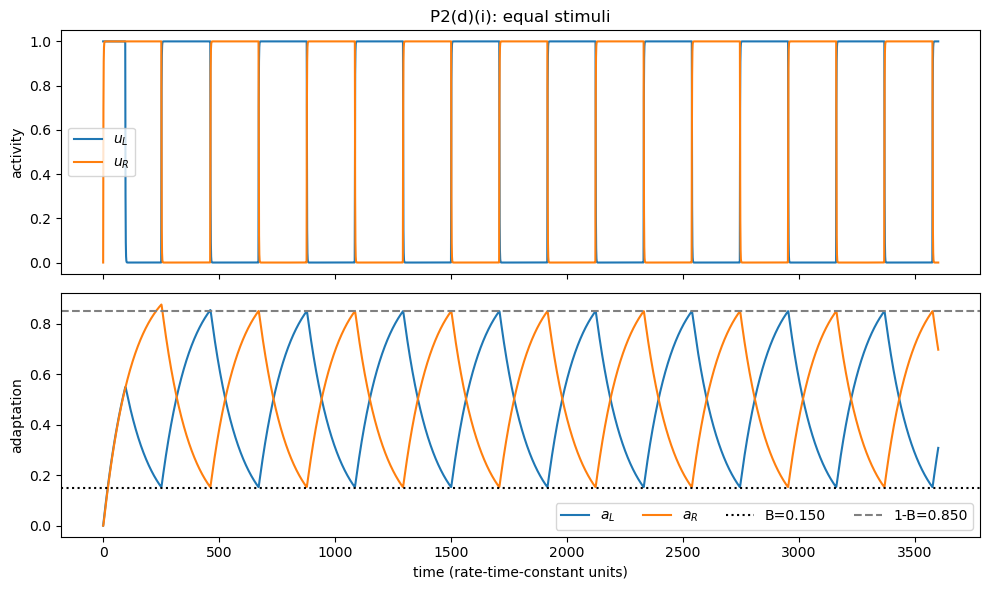

In [15]:
#rate, adaption traces/thresholds
t,uL,uR,aL,aR = run_equal
B = (1.3-BETA)/G
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(10,6),sharex=True)
ax1.plot(t,uL,label=r'$u_L$'); ax1.plot(t,uR,label=r'$u_R$')
ax1.set(ylabel='activity',title='P2(d)(i): equal stimuli'); ax1.legend()
ax2.plot(t,aL,label=r'$a_L$'); ax2.plot(t,aR,label=r'$a_R$')
ax2.axhline(B,color='black',ls=':',label=f'B={B:.3f}')
ax2.axhline(1-B,color='gray',ls='--',label=f'1-B={1-B:.3f}')
ax2.set(xlabel='time (rate-time-constant units)',ylabel='adaptation');ax2.legend(ncol=4)
plt.tight_layout();plt.show()

In [17]:
#Levelt comparison
rows=[]
for IL in [1.3,1.45,1.6]:
    run=rivalry_run(IL)
    measured=rivalry_durations(run)
    BL, BR, TL, TR=analytic_rivalry(IL)
    rows.append(dict(IL=IL, IR=1.3, TL_sim=measured['TL'], TR_sim=measured['TR'],
                     TL_theory=TL, TR_theory=TR,
                     TL_difference=measured['TL']-TL, TR_difference=measured['TR']-TR))
p2ii=pd.DataFrame(rows)
display(p2ii.round(3))
print('Sign convention: discrepancy = simulated duration - Heaviside prediction')

,IL,IR,TL_sim,TR_sim,TL_theory,TR_theory,TL_difference,TR_difference
0,1.30,1.3,207.492,207.491,208.152,208.152,-0.660,-0.661
1,1.45,1.3,197.141,160.088,197.067,159.496,0.073,0.592
2,1.60,1.3,186.127,126.590,184.853,124.974,1.274,1.616


Sign convention: discrepancy = simulated duration - Heaviside prediction


In [18]:
#change w=3
run_loww=rivalry_run(1.3, w=0.3)
measured_loww=rivalry_durations(run_loww)
T_pred = TAU_A*np.log((0.3+1.3)/(G-0.3-1.3))
print(f'w=0.3: predicted Tdom = {T_pred:.3f} time units')
print(f'simulated L = {measured_loww["TL"]:.3f}, R = {measured_loww["TR"]:.3f}')
print(f'difference (L) = {measured_loww["TL"]-T_pred:+.3f}')

w=0.3: predicted Tdom = 166.355 time units
simulated L = 166.196, R = 166.229
difference (L) = -0.160


## 3d
Based on oct 26, 28 provided ipynb

In [19]:
DX, DT = 0.02, 0.02
X = np.arange(-20,20+0.5*DX,DX)
N = X.size

def mexican(z):
    z=np.abs(z)
    return 2*np.exp(-z)-np.exp(-z/2)

def Wprimitive(z):
    # integral from 0 to z of w(s) ds; odd since w is even
    a=np.abs(z)
    out=2*(np.exp(-a/2)-np.exp(-a))
    return np.sign(z)*out

def bump_widths(kappa):
    S=np.sqrt(1-2*kappa)
    am=-np.log((1+S)/2)
    ap=-np.log((1-S)/2)
    return am,ap

def lambda_even(a):
    w2a=mexican(2*a)
    return 2*w2a/(mexican(0)-w2a)

# Linear, nonperiodic convolution w(x-y)*g(y) with FFT padding.
# Kernel indices correspond to differences -(N-1),...,N-1.
K = mexican(np.arange(-(N-1),N)*DX)
FFT_SIZE=next_fast_len(3*N-2)
KHAT = rfft(K, n=FFT_SIZE)

def convolve_zero_padded(g):
    full = irfft(KHAT*rfft(g, n=FFT_SIZE),n=FFT_SIZE)
    return DX*full[N-1:2*N-1]

# Check FFT convolution against direct quadrature at a few grid points.
test_g=np.exp(-X**2)
test_conv=convolve_zero_padded(test_g)
for j in [N//2-50,N//2,N//2+50]:
    direct=DX*np.sum(mexican(X[j]-X)*test_g)
    assert abs(direct-test_conv[j])<1e-10
print(f'Grid N={N}, dx={DX}, dt={DT}; zero-padded convolution validated.')
for kap in [0.1,0.3,0.45]:
    am,ap=bump_widths(kap)
    print(f'kappa={kap}: a-={am:.5f}, a+={ap:.5f}, lambda_e(wide)={lambda_even(ap):+.5f}')

Grid N=2001, dx=0.02, dt=0.02; zero-padded convolution validated.
kappa=0.1: a-=0.05423, a+=2.94150, lambda_e(wide)=-0.09017
kappa=0.3: a-=0.20306, a+=1.69406, lambda_e(wide)=-0.20825
kappa=0.45: a-=0.41838, a+=1.07328, lambda_e(wide)=-0.19513


In [20]:
#interpolating 2 threshold crossing
def active_halfwidth(u,kappa):
    active = u >= kappa
    center = np.argmin(np.abs(X))
    if not active[center]:
        # losing central active component
        return 0.0
    left=center
    while left>0 and active[left-1]: left-=1
    right=center
    while right<N-1 and active[right+1]: right+=1
    if left==0 or right==N-1: return np.nan  # hit boundary
    xleft = X[left-1]+(kappa-u[left-1])*(X[left]-X[left-1])/(u[left]-u[left-1])
    xright= X[right]+(kappa-u[right])*(X[right+1]-X[right])/(u[right+1]-u[right])
    return 0.5*(xright-xleft)

def run_bump(kappa, a0, t_end=80, sample_every=5):
    u = Wprimitive(X+a0)-Wprimitive(X-a0)
    widths=[]; times=[]
    for n in range(int(round(t_end/DT))+1):
        if n%sample_every==0:
            times.append(n*DT)
            widths.append(active_halfwidth(u,kappa))
        if n==int(round(t_end/DT)): break
        rate=expit(100*(u-kappa))
        u += DT*(-u+convolve_zero_padded(rate))
    return np.array(times),np.array(widths),u

narrow - 0.02   : final half-width=0.0000
narrow + 0.02   : final half-width=1.6942
wide - 0.05     : final half-width=1.6942
wide + 0.05     : final half-width=1.6942


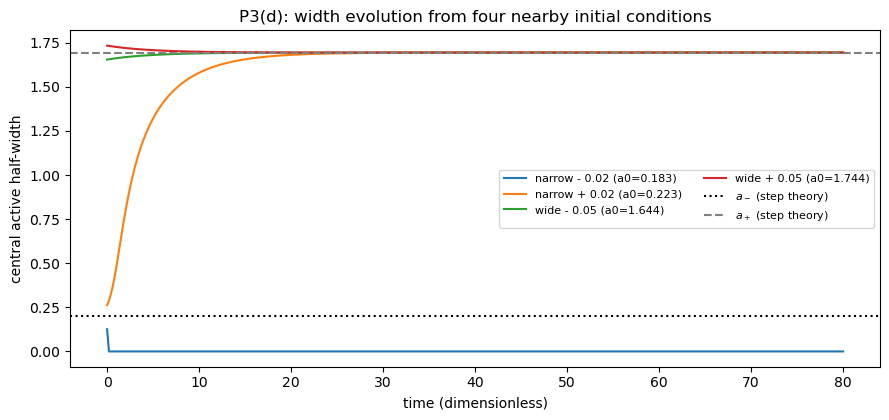

In [22]:
#narrow/wide bumps above/below width
kappa=0.3
am,ap=bump_widths(kappa)
fig, ax=plt.subplots(figsize=(9,4.3))
p3first={}
for name,a0 in [('narrow - 0.02',am-0.02),('narrow + 0.02',am+0.02),
                ('wide - 0.05',ap-0.05),('wide + 0.05',ap+0.05)]:
    t,h,u=run_bump(kappa,a0,t_end=80)
    p3first[name]=(t,h)
    ax.plot(t,h,label=f'{name} (a0={a0:.3f})')
    print(f'{name:16s}: final half-width={h[-1]:.4f}')
ax.axhline(am,ls=':',color='black',label=r'$a_-$ (step theory)')
ax.axhline(ap,ls='--',color='gray',label=r'$a_+$ (step theory)')
ax.set(xlabel='time (dimensionless)',ylabel='central active half-width',
       title='P3(d): width evolution from four nearby initial conditions')
ax.legend(ncol=2,fontsize=8);plt.tight_layout();plt.show()

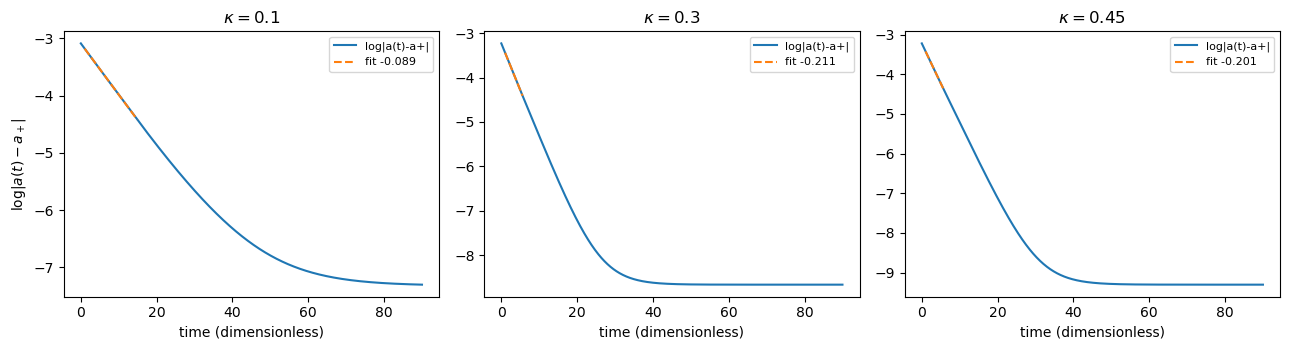

,kappa,rate_fit,lambda_even_theory,fit_t_min,fit_t_max,final_width,analytic_width
0,0.10,-0.0893,-0.0902,1.0,14.9,2.9422,2.9415
1,0.30,-0.2107,-0.2083,1.0,5.6,1.6942,1.6941
2,0.45,-0.2007,-0.1951,1.0,5.9,1.0734,1.0733


In [24]:
#wide-bump relaxation rate
fig,axs=plt.subplots(1,3,figsize=(13,3.6),sharey=False)
p3rates=[]
for ax,kap in zip(axs,[0.1,0.3,0.45]):
    am,ap=bump_widths(kap)
    t,h,_=run_bump(kap,ap+0.05,t_end=90,sample_every=5)
    diff=np.abs(h-ap)
    # Use a mid-transient window, before finite-gain stationary bias dominates.
    # Prefer a near-exponential phase with 0.01 < abs(width error) < 0.045.
    fit=(t>=1)&(t<=40)&(diff>0.012)&(diff<0.045)&np.isfinite(diff)
    if np.count_nonzero(fit)<8:
        fit=(t>=2)&(t<=25)&(diff>1e-4)&np.isfinite(diff)
    fit_rate,fit_intercept=np.polyfit(t[fit],np.log(diff[fit]),1)
    ax.plot(t,np.log(np.maximum(diff,1e-10)),label='log|a(t)-a+|')
    ax.plot(t[fit],fit_intercept+fit_rate*t[fit],'--',label=f'fit {fit_rate:+.3f}')
    ax.set(title=f'$\kappa={kap}$',xlabel='time (dimensionless)')
    ax.legend(fontsize=8)
    p3rates.append(dict(kappa=kap,rate_fit=fit_rate,lambda_even_theory=lambda_even(ap),
                        fit_t_min=t[fit].min(),fit_t_max=t[fit].max(),
                        final_width=h[-1],analytic_width=ap))
axs[0].set_ylabel(r'$\log|a(t)-a_+|$')
plt.tight_layout();plt.show()
p3rates_df=pd.DataFrame(p3rates)
display(p3rates_df.round(4))
#compare signs and magnitudes, finite sigmoid gain and width bias affect fitted slopes